In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [122]:
df=pd.read_csv('D:\Programs\portfolio\MachineLearning\DataSets\placement.csv')

In [123]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


C:\Users\Zahoor\AppData\Local\Temp\ipykernel_6824\2766579274.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'])


C:\Users\Zahoor\AppData\Local\Temp\ipykernel_6824\2766579274.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['placement_exam_marks'])


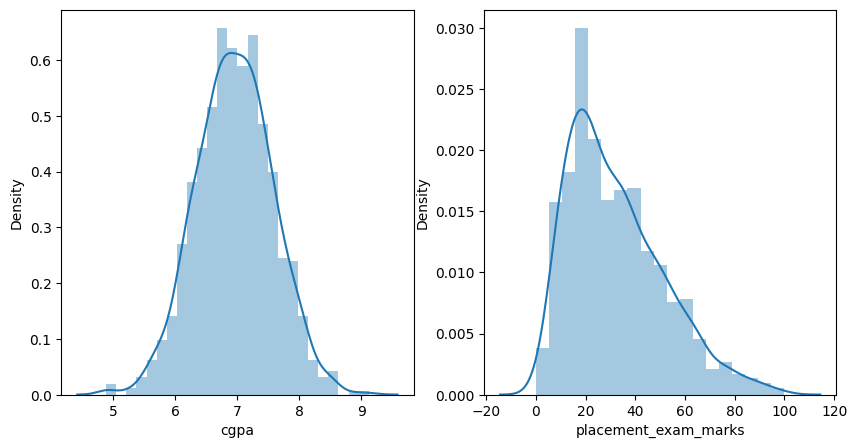

In [124]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.distplot(df['cgpa'])

plt.subplot(1,2,2)
sns.distplot(df['placement_exam_marks'])

plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x274b723d810>,
 'caps': [<matplotlib.lines.Line2D at 0x274b723da90>,
 'boxes': [<matplotlib.lines.Line2D at 0x274b723d6d0>],
 'medians': [<matplotlib.lines.Line2D at 0x274b723dd10>],
 'fliers': [<matplotlib.lines.Line2D at 0x274b723de50>],
 'means': []}

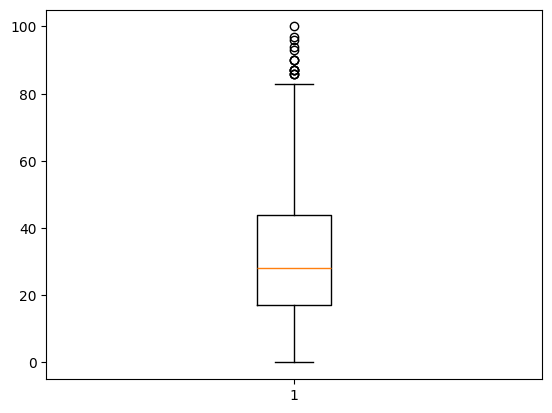

In [125]:
plt.boxplot(df['placement_exam_marks'])

In [126]:
df.describe()


,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961240,32.225000,0.489000
std,0.615898,19.130822,0.500129
min,4.890000,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,9.120000,100.000000,1.000000


In [127]:
print("Min value of placement_exam_marks is: ",df['placement_exam_marks'].min())

print("Max value of placement_exam_marks is: ",df['placement_exam_marks'].max())

Min value of placement_exam_marks is:  0.0
Max value of placement_exam_marks is:  100.0


In [128]:
percentile25 = np.percentile(df['placement_exam_marks'], 25)
percentile75 = np.percentile(df['placement_exam_marks'], 75)

In [129]:
percentile25

np.float64(17.0)

In [130]:
percentile75

np.float64(44.0)

In [131]:
Iqr = percentile75 - percentile25

In [132]:
upper_limit = percentile75 + 1.5 * Iqr
lower_limit = percentile25 - 1.5 * Iqr


In [133]:
lower_limit

np.float64(-23.5)

# Finding outliers

In [134]:
outliers = df[(df['placement_exam_marks'] > upper_limit) | (df['placement_exam_marks'] < lower_limit)]
outliers

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


## Trimming

In [135]:
new_df = df[(df['placement_exam_marks'] <= upper_limit)]

In [136]:
new_df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [137]:
new_df.describe()

,cgpa,placement_exam_marks,placed
count,985.000000,985.000000,985.00000
mean,6.961594,31.339086,0.48934
std,0.614734,17.857633,0.50014
min,4.890000,0.000000,0.00000
25%,6.550000,17.000000,0.00000
50%,6.960000,28.000000,0.00000
75%,7.370000,43.000000,1.00000
max,9.120000,83.000000,1.00000


In [138]:
df.describe()

,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961240,32.225000,0.489000
std,0.615898,19.130822,0.500129
min,4.890000,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,9.120000,100.000000,1.000000


## capping

<Axes: ylabel='placement_exam_marks'>

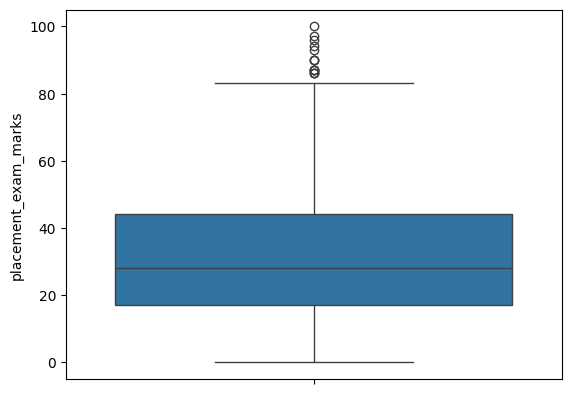

In [146]:
sns.boxplot(df['placement_exam_marks'])

In [147]:
df['placement_exam_marks'] = np.where(
    df['placement_exam_marks'] > upper_limit,
    upper_limit,
    np.where(
        df['placement_exam_marks'] < lower_limit,
        lower_limit,
        df['placement_exam_marks']
    )
)

<Axes: ylabel='placement_exam_marks'>

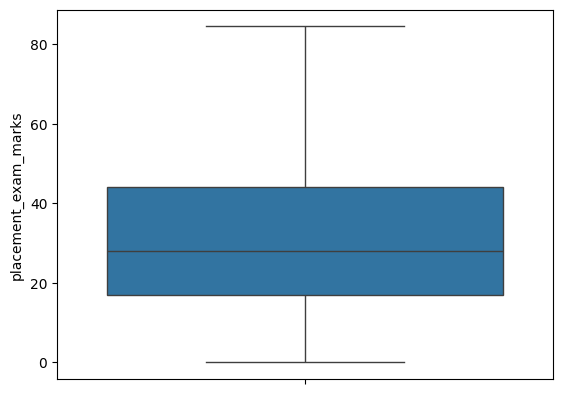

In [148]:
sns.boxplot(df['placement_exam_marks'])

<Axes: ylabel='cgpa'>

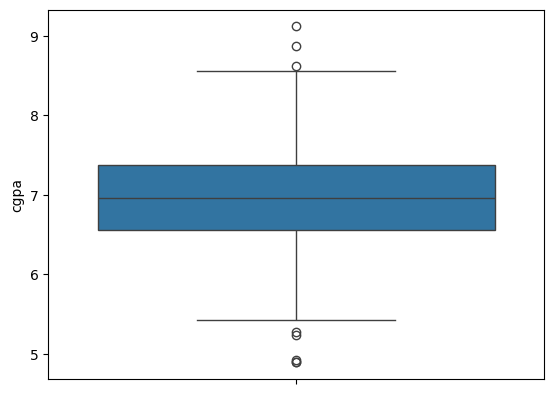

In [149]:
sns.boxplot(df['cgpa'])

In [150]:
cgpa_percentile25 = np.percentile(df['cgpa'], 25)
cgpa_percentile75 = np.percentile(df['cgpa'], 75)

In [151]:
cgpa_Iqr = cgpa_percentile75 - cgpa_percentile25

In [153]:
cgpa_higher_limit = cgpa_percentile75 + 1.5 *cgpa_Iqr

cgpa_lower_limit = cgpa_percentile25 - 1.5* cgpa_Iqr

## Capping

In [154]:
df['cgpa'] = np.where(
    df['cgpa'] > cgpa_higher_limit,
    cgpa_higher_limit,
    np.where(
        df['cgpa'] < cgpa_lower_limit,
        cgpa_lower_limit,
        df['cgpa']

    )
)

<Axes: ylabel='cgpa'>

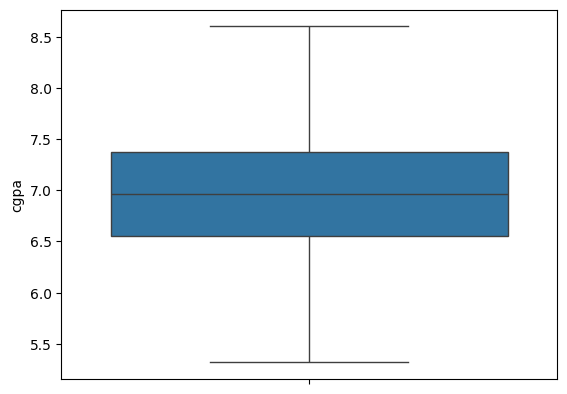

In [155]:
sns.boxplot(df['cgpa'])

<Axes: ylabel='placed'>

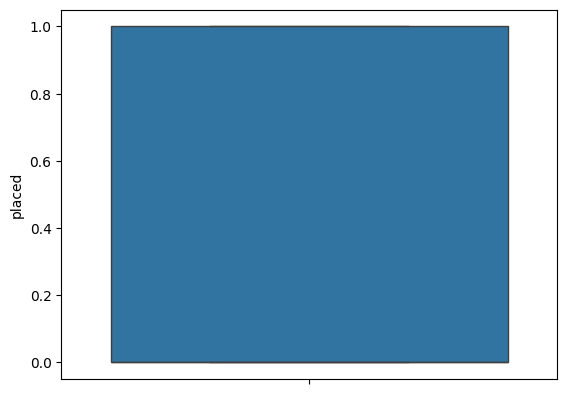

In [156]:
sns.boxplot(df['placed'])

In [157]:
df['placed'].skew()

np.float64(0.04407679462601847)

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_6824\3382675032.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['placed'])


<Axes: xlabel='placed', ylabel='Density'>

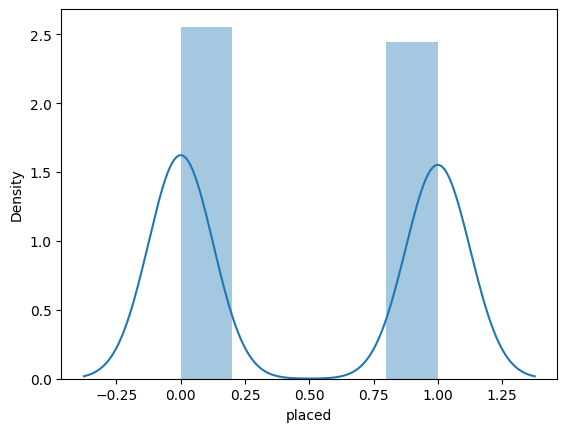

In [158]:
sns.distplot(df['placed'])